# 第三周作业演示：全币种 5 分钟 K 线数据库

用一行 `load_klines` 读取 10 个币一周的 5 分钟 K 线，并画出其中一个币的收盘价。

In [ ]:
from src.cls.data import list_symbols, load_klines

# 取本地已有数据的前 10 个币
symbols = list_symbols()["symbol"].head(10).tolist()
print("10 个币:", symbols)

10 个币: ['0GUSDT', '1000000MOGUSDT', '1000BONKUSDT', '1000CATUSDT', '1000CHEEMSUSDT', '1000FLOKIUSDT', '1000LUNCUSDT', '1000PEPEUSDT', '1000RATSUSDT', '1000SATSUSDT']


In [ ]:
# 一行 load_klines 读取 10 个币一周的 5 分钟 K 线
df = load_klines(symbols, "2026-10-01", "2026-10-08")

In [ ]:
print(f"shape: {df.shape}")
df.head()

shape: (20160, 13)


           symbol                 open_time      open      high       low     close      volume                       close_time   quote_volume  count  taker_buy_volume  taker_buy_quote_volume  ignore
0          0GUSDT 2026-10-01 00:00:00+00:00  0.310900  0.314000  0.309100  0.311700   2103898.0 2026-10-01 00:04:59.999000+00:00  654984.293500   5699         1153212.0           359392.146300       0
1  1000000MOGUSDT 2026-10-01 00:00:00+00:00  0.116300  0.116400  0.116000  0.116000     23368.9 2026-10-01 00:04:59.999000+00:00    2715.550640    102            3241.3              376.846310       0
2    1000BONKUSDT 2026-10-01 00:00:00+00:00  0.003798  0.003800  0.003777  0.003784  25645638.0 2026-10-01 00:04:59.999000+00:00   97114.417049    852         6718740.0            25446.846255       0
3     1000CATUSDT 2026-10-01 00:00:00+00:00  0.002281  0.002283  0.002275  0.002276    546878.0 2026-10-01 00:04:59.999000+00:00    1245.875484     74          213868.0              487.182967    

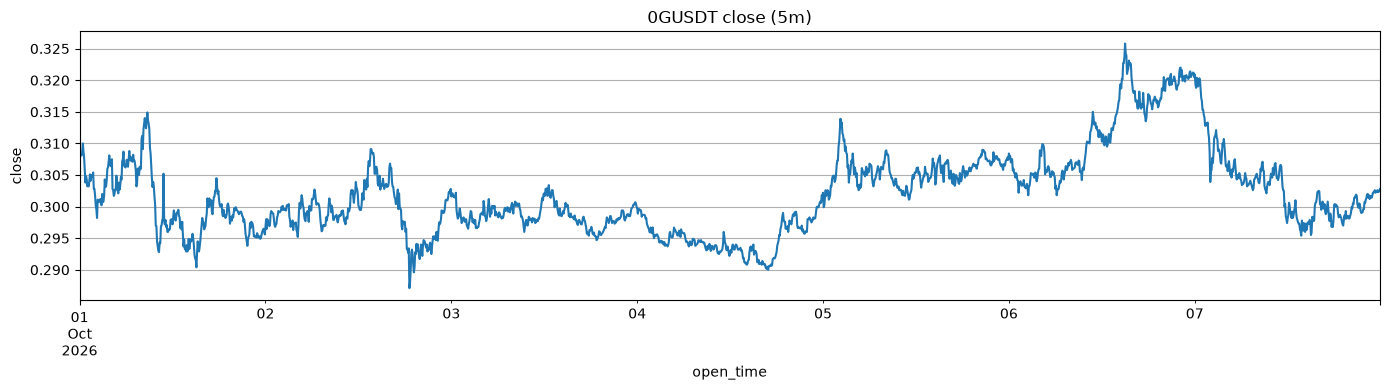

In [ ]:
# 画出其中一个币（第一个）的收盘价
import matplotlib.pyplot as plt

sym = symbols[0]
series = df[df["symbol"] == sym].set_index("open_time")["close"]
series.plot(figsize=(14, 4), title=f"{sym} close (5m)", grid=True)
plt.ylabel("close")
plt.tight_layout()
plt.show()